# Experiment 4: Implementation of Simon's Algorithm Using Qiskit

**Course:** Quantum Computing and Algorithms  
**Name:** Ritesh Roshan Sahoo  
**Roll Number:** DL.AI.U4AID24036  
**Email:** riteshroshansahoo01@gmail.com

## Aim

To implement and investigate Simon's algorithm using Qiskit for identifying a hidden XOR relationship in a black-box function, and to study its applications in hidden-pattern detection, reverse engineering, cryptography and noisy quantum computation.

## Setup

In [1]:
%pip install --quiet qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

backend = AerSimulator()

# Simon oracle: copy x into the output register, then XOR s into it
# whenever the first 1-bit of s is set, so that f(x) = f(x XOR s).
# Qubit i holds bit i counted from the right of the string.
def simon_oracle(qc, s):
    n = len(s)
    bits = s[::-1]
    for i in range(n):
        qc.cx(i, n + i)
    j = bits.index("1")
    for i, bit in enumerate(bits):
        if bit == "1":
            qc.cx(j, n + i)

# y . s mod 2 for two bit strings
def dot(y, s):
    return sum(int(a) * int(b) for a, b in zip(y, s)) % 2

# Rank of a set of bit strings over GF(2)
def gf2_rank(ys):
    rows = [int(y, 2) for y in ys]
    rank = 0
    for col in range(len(ys[0]) - 1, -1, -1):
        pivot = next((r for r in rows if r >> col & 1), None)
        if pivot is None:
            continue
        rows.remove(pivot)
        rows = [r ^ pivot if r >> col & 1 else r for r in rows]
        rank += 1
    return rank

# Solve y . s = 0 for every measured y by exhaustive search over GF(2)^n
def recover_s(ys, n):
    return [format(v, f"0{n}b") for v in range(1, 2**n)
            if all(dot(y, format(v, f"0{n}b")) == 0 for y in ys)]

## Task 1: Hidden Pattern Identification

### Problem Statement

A black-box function satisfies $f(x) = f(x \oplus s)$ with hidden string $s = 101$. Construct the Simon oracle, execute Simon's algorithm, collect the measurement results, verify that every measured $y$ satisfies $y \cdot s = 0 \pmod 2$ and recover $s$.

### Program

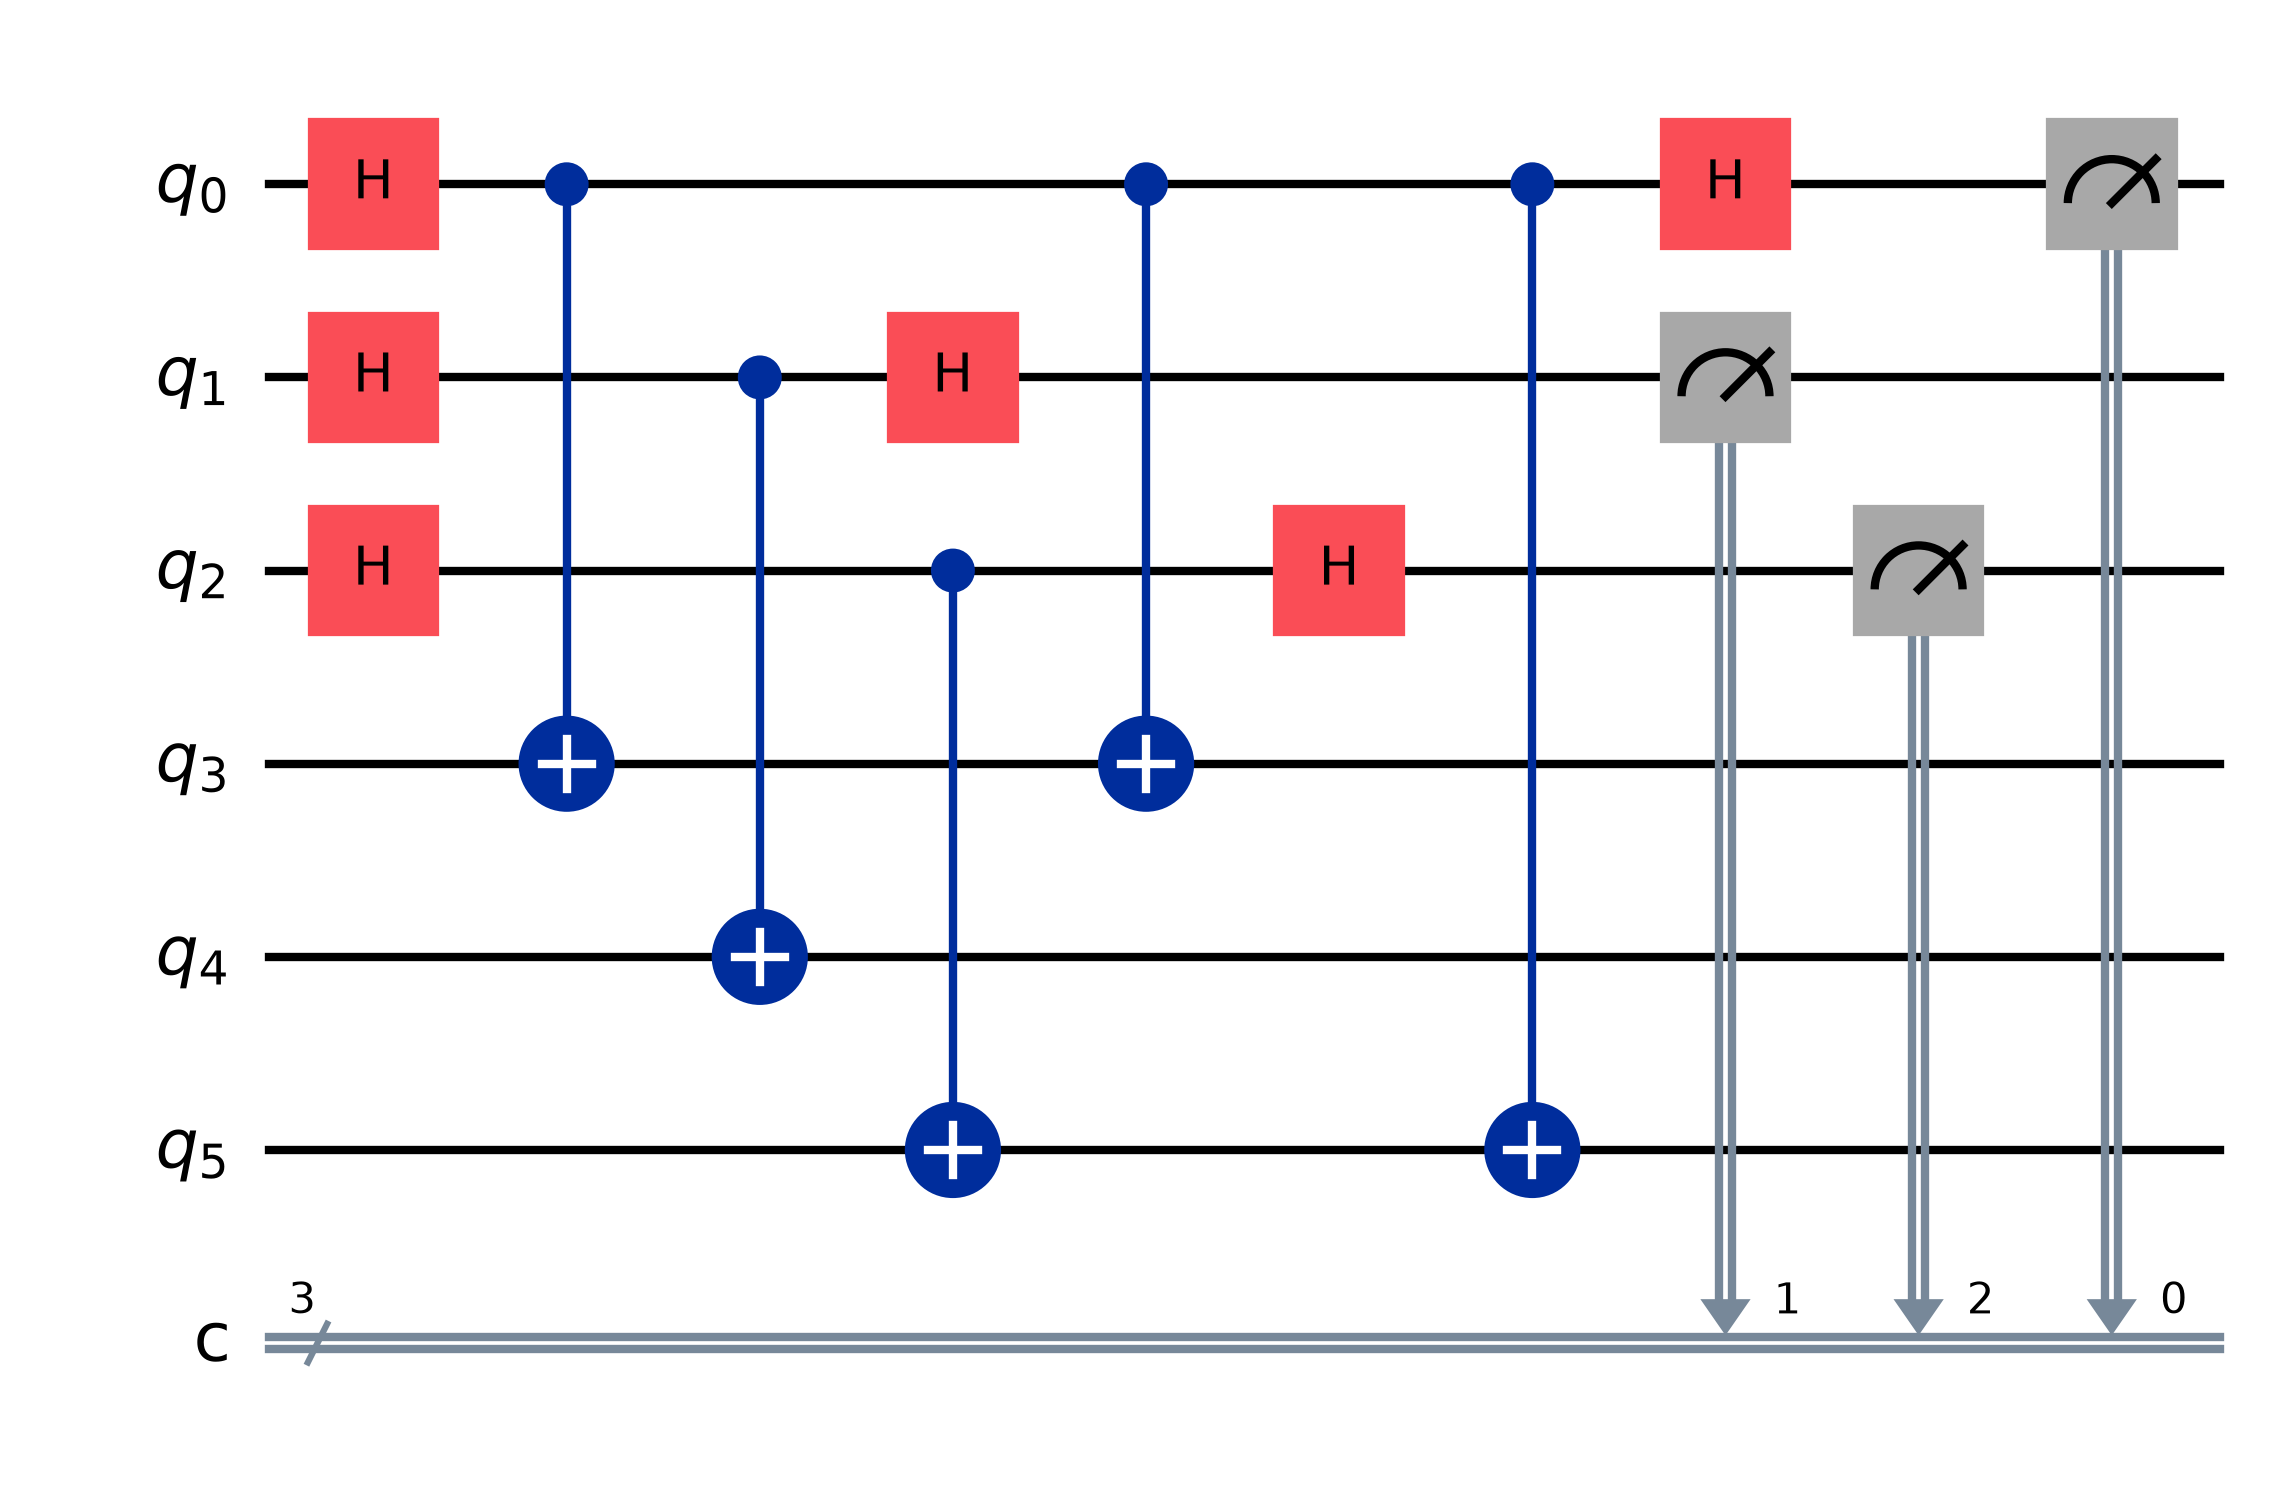

Measurement Results: {'101': 243, '010': 268, '000': 250, '111': 263}


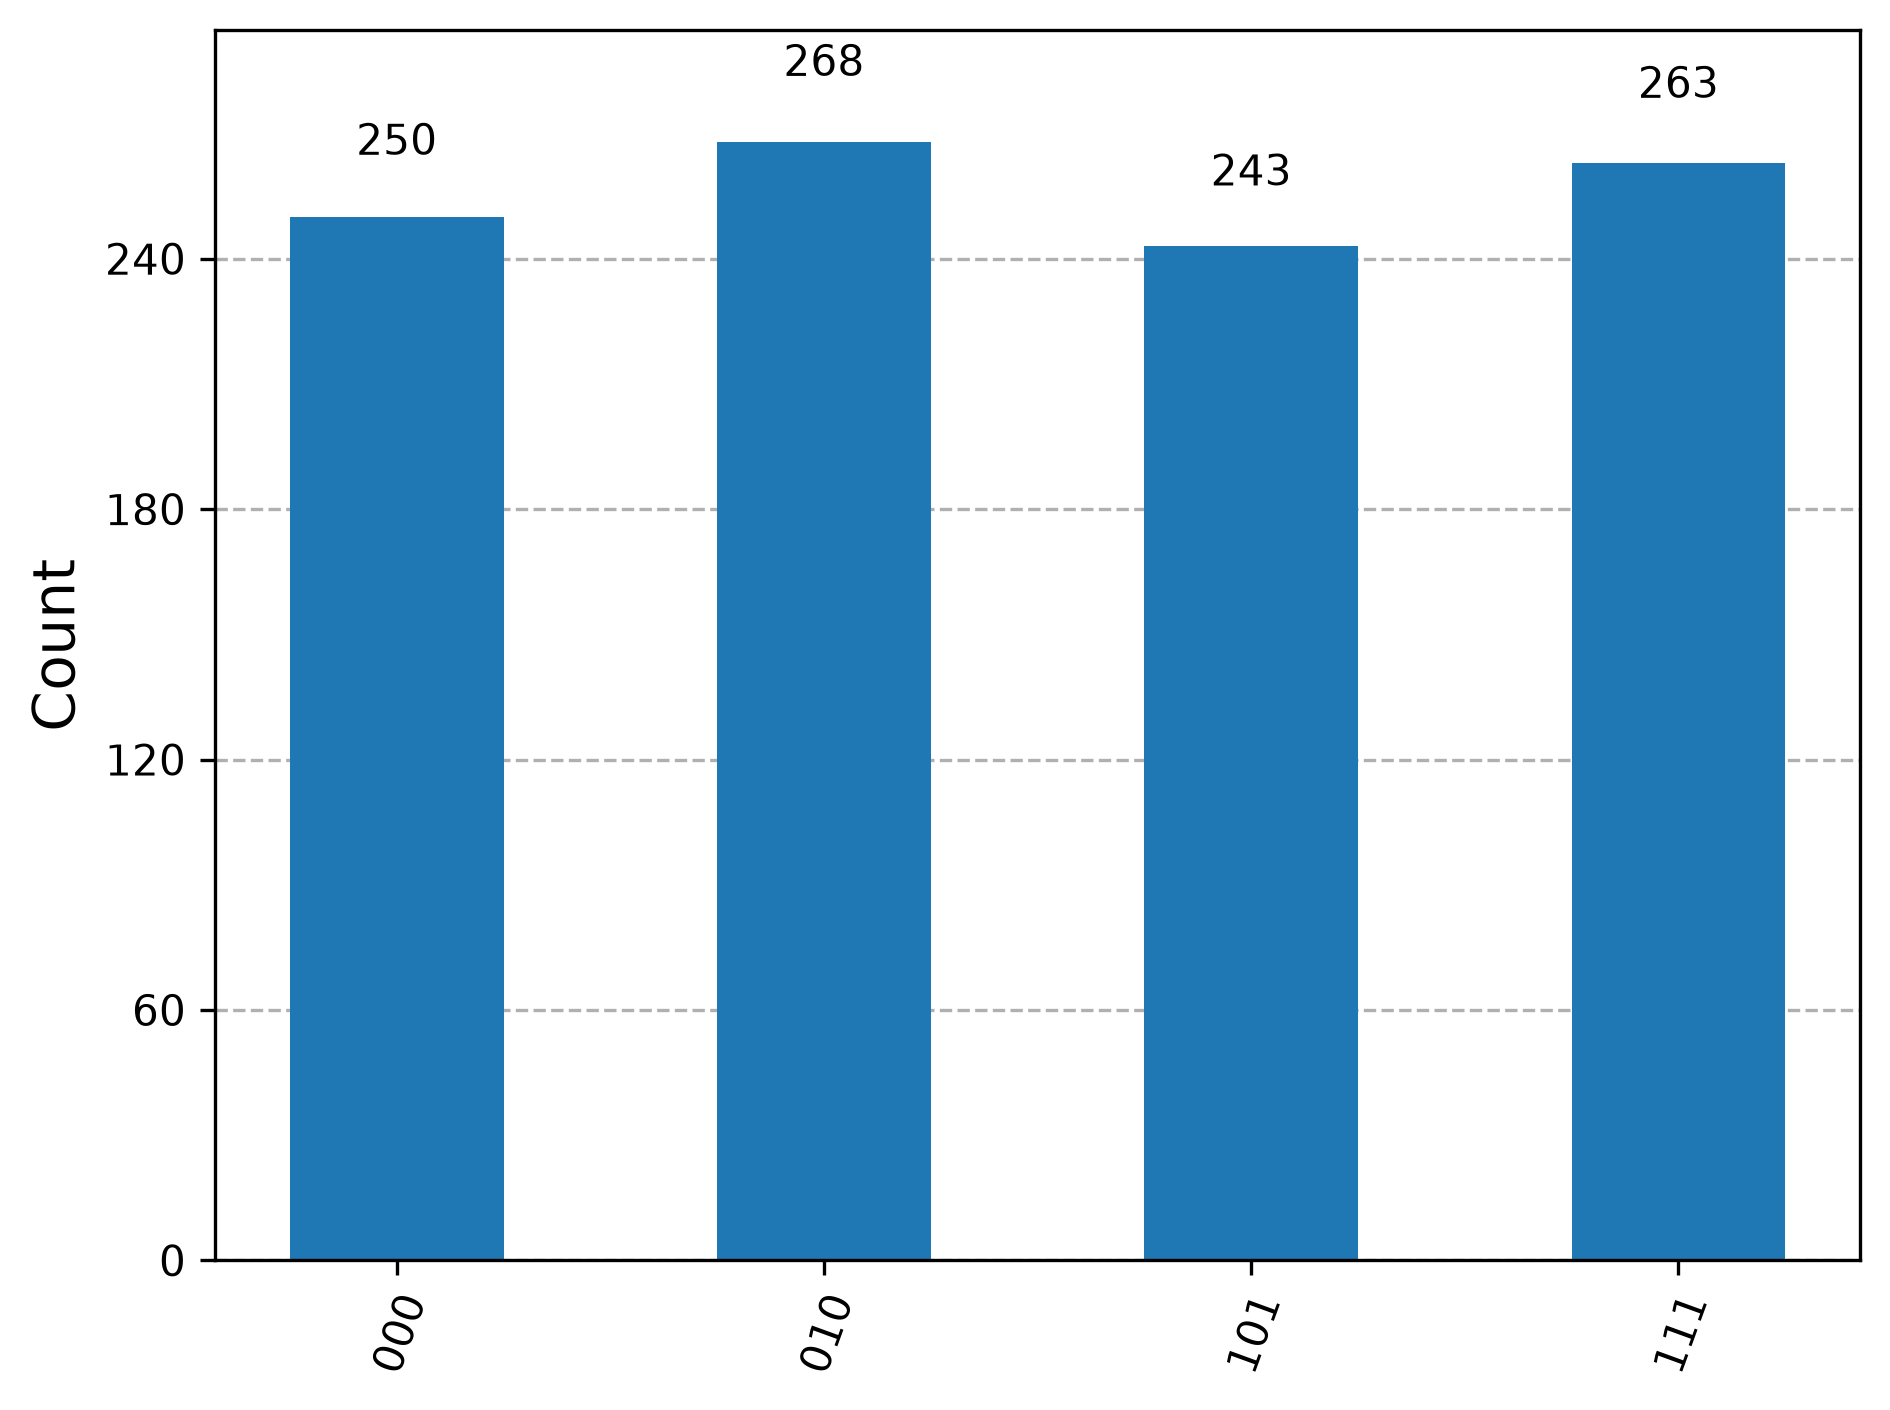

In [3]:
s = "101"
n = len(s)

qc = QuantumCircuit(2 * n, n)

# Hadamard on input register
qc.h(range(n))

# Simon Oracle
simon_oracle(qc, s)

# Second Hadamard
qc.h(range(n))

# Measurement
qc.measure(range(n), range(n))

display(qc.draw("mpl"))

result = backend.run(
    transpile(qc, backend), shots=1024
).result()
counts = result.get_counts()

print("Measurement Results:", counts)
display(plot_histogram(counts))

In [4]:
# Verify y . s = 0 (mod 2) and recover s
ys = sorted(counts)
for y in ys:
    print(f"y = {y}, y . {s} = {dot(y, s)}")

print("Independent equations:", gf2_rank(ys))
print("Recovered s:", recover_s(ys, n))

y = 000, y . 101 = 0
y = 010, y . 101 = 0
y = 101, y . 101 = 0
y = 111, y . 101 = 0
Independent equations: 2
Recovered s: ['101']


### Observation

Only four of the eight possible strings appear: **000, 010, 101 and 111**, each with about a quarter of the shots. Every one of them satisfies $y \cdot 101 = 0 \pmod 2$, the non-zero ones give **2 independent equations**, and the only non-zero solution is **$s = 101$**. The zero string carries no information, which is why several shots are needed.

## Task 2: Black-Box Duplicate Detection

### Problem Statement

A data-processing system behaves according to $f(x) = f(x \oplus s)$ and only the oracle is accessible. Interpreting $x$ and $x \oplus s$ as two records that produce the same output, determine the hidden string by collecting measured $y$ values, writing the equation $y \cdot s = 0$ for each one and solving them once enough independent equations are available.

### Program

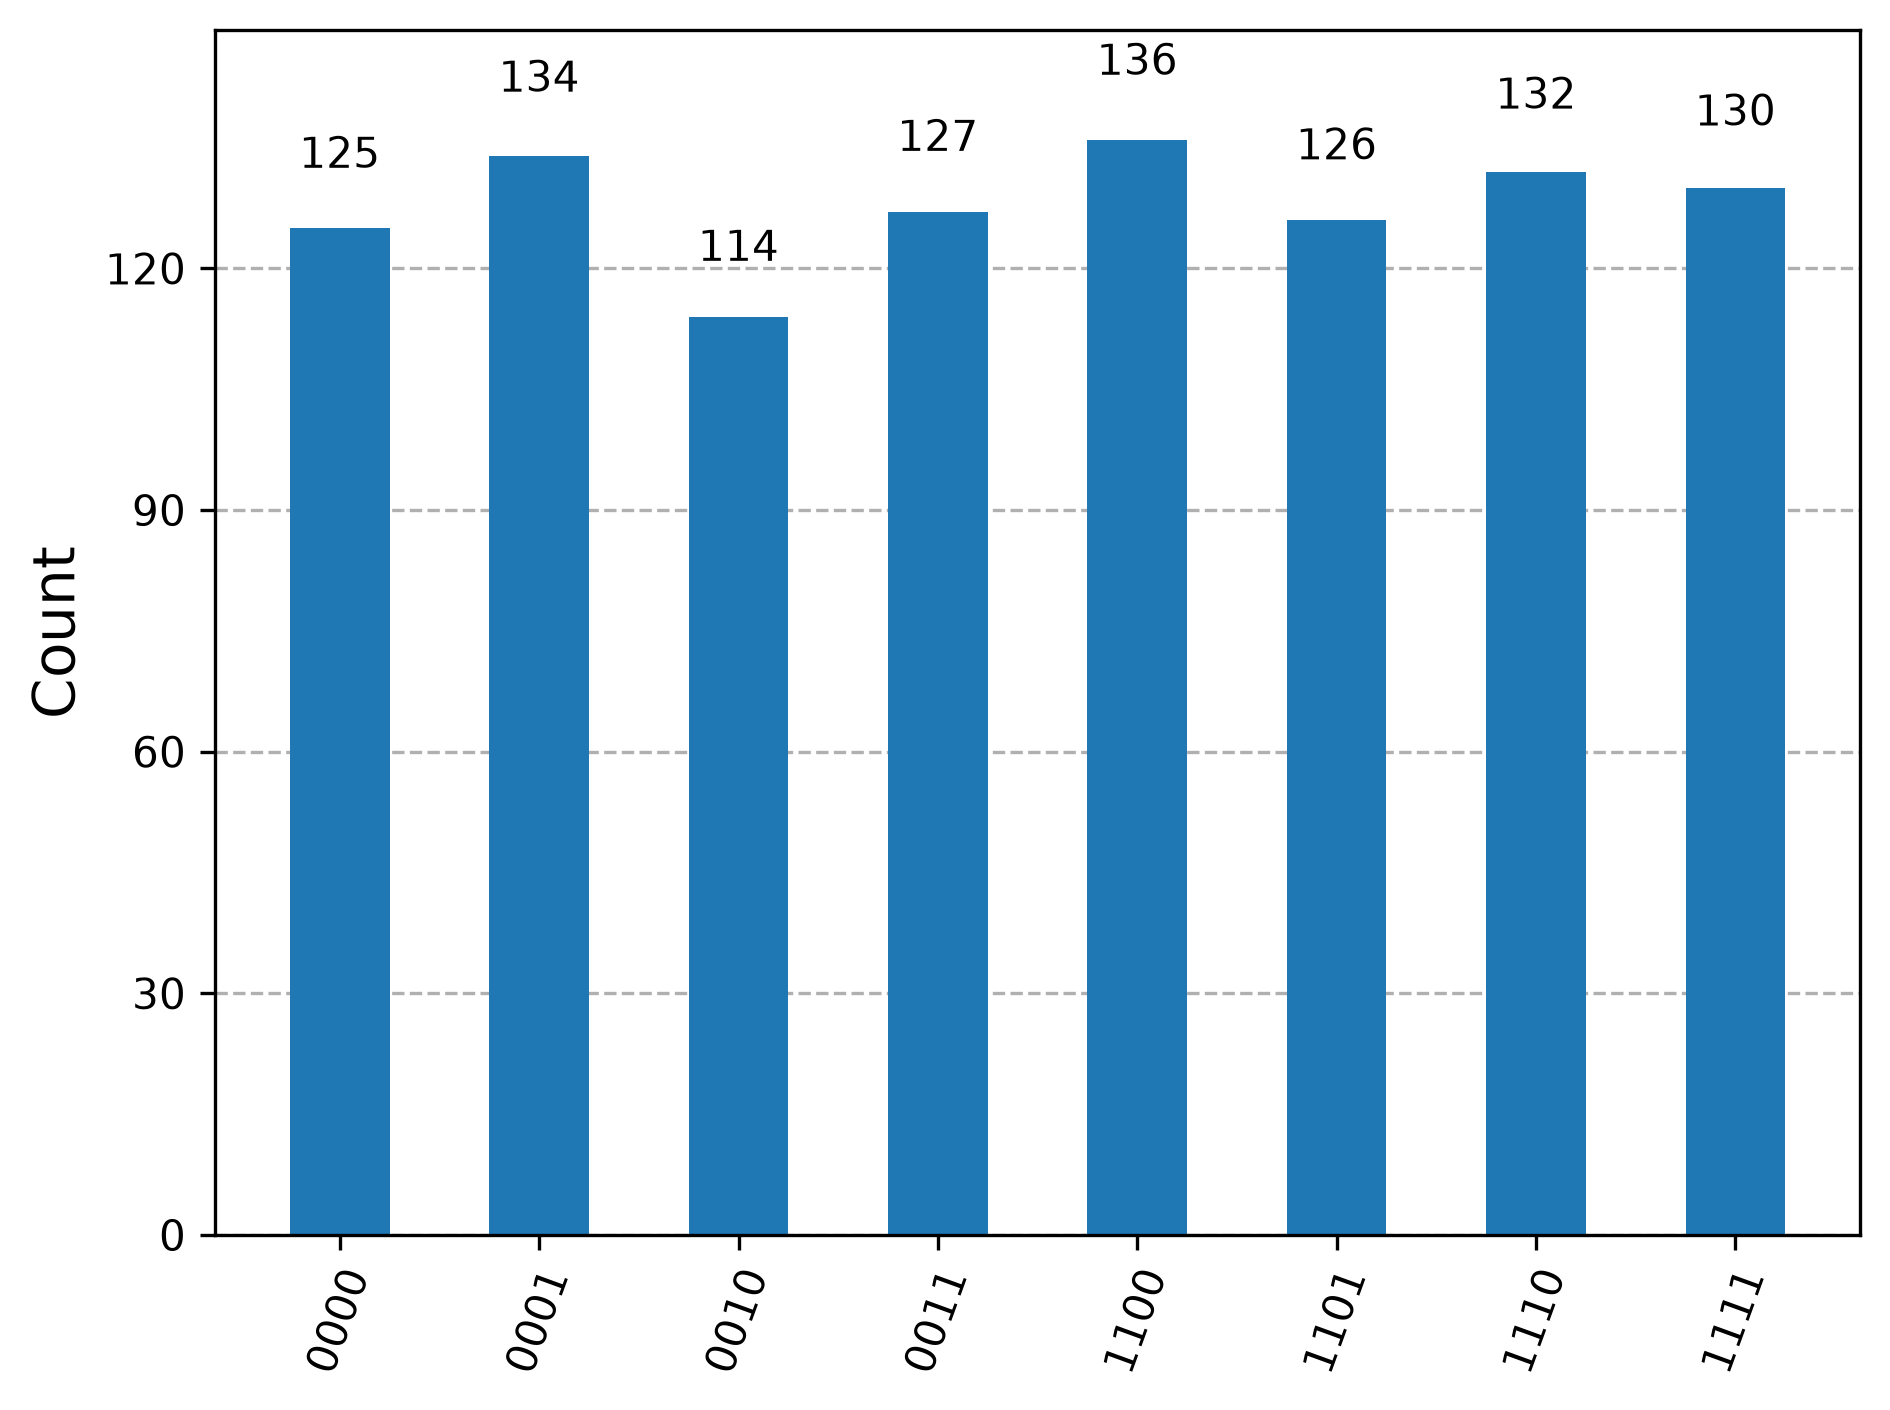

Measured y     equation          y . s
0000            = 0              0
0001           s3 = 0            0
0010           s2 = 0            0
0011           s2 + s3 = 0       0
1100           s0 + s1 = 0       0
1101           s0 + s1 + s3 = 0  0
1110           s0 + s1 + s2 = 0  0
1111           s0 + s1 + s2 + s3 = 0 0

Independent equations: 3 (need 3 )
Recovered s: ['1100']


In [5]:
s = "1100"
n = len(s)

qc = QuantumCircuit(2 * n, n)
qc.h(range(n))
simon_oracle(qc, s)
qc.h(range(n))
qc.measure(range(n), range(n))

counts = backend.run(
    transpile(qc, backend), shots=1024
).result().get_counts()
display(plot_histogram(counts))

print("Measured y     equation          y . s")
for y in sorted(counts):
    terms = " + ".join(f"s{i}" for i, b in enumerate(y) if b == "1")
    print(f"{y:<12}   {terms + ' = 0':<17} {dot(y, s)}")

ys = [y for y in counts if y != "0" * n]
print("\nIndependent equations:", gf2_rank(ys), "(need", n - 1, ")")
print("Recovered s:", recover_s(ys, n))

In [6]:
# Duplicate records: x and x XOR s give the same output
def xor(a, b):
    return "".join(str(int(p) ^ int(q)) for p, q in zip(a, b))

def query_oracle(x):
    n = len(x)
    qc = QuantumCircuit(2 * n, n)
    for i, bit in enumerate(reversed(x)):
        if bit == "1":
            qc.x(i)
    simon_oracle(qc, s)
    qc.measure(range(n, 2 * n), range(n))
    counts = backend.run(transpile(qc, backend), shots=1).result()
    return list(counts.get_counts())[0]

for x in ["0000", "0101", "1010", "0011"]:
    print(f"f({x}) = {query_oracle(x)},",
          f"f({xor(x, s)}) = {query_oracle(xor(x, s))}")

f(0000) = 0000, f(1100) = 0000


f(0101) = 1001, f(1001) = 1001


f(1010) = 1010, f(0110) = 1010


f(0011) = 0011, f(1111) = 0011


### Observation

- **Why the orthogonality holds**: after the oracle the input register is in $(|x\rangle + |x \oplus s\rangle)/\sqrt{2}$; the second Hadamard layer gives amplitude proportional to $(-1)^{x \cdot y}(1 + (-1)^{s \cdot y})$, which vanishes unless $s \cdot y = 0$.
- **Equations required**: $n - 1$ linearly independent ones, here 3 for $n = 4$, which the run collected.
- **Different results, same $s$**: yes, all $2^{n-1}$ strings orthogonal to $s$ are valid outcomes of the same oracle.
- **Oracle uniqueness**: no, any reversible circuit with the same collision structure is a valid oracle.
- Querying the oracle directly confirmed that **$x$ and $x \oplus 1100$ always give the same output**, which is the duplicate-record relationship.

## Task 3: Reverse Engineering a Black-Box System

### Problem Statement

A Simon oracle is supplied as a black box and the hidden string is not provided. Build the Simon circuit around it, collect measurement data, convert the measurements into equations, solve them over GF(2), recover the hidden string, verify it by testing the oracle on random inputs and report the number of oracle queries and whether the solution is unique.

### Program

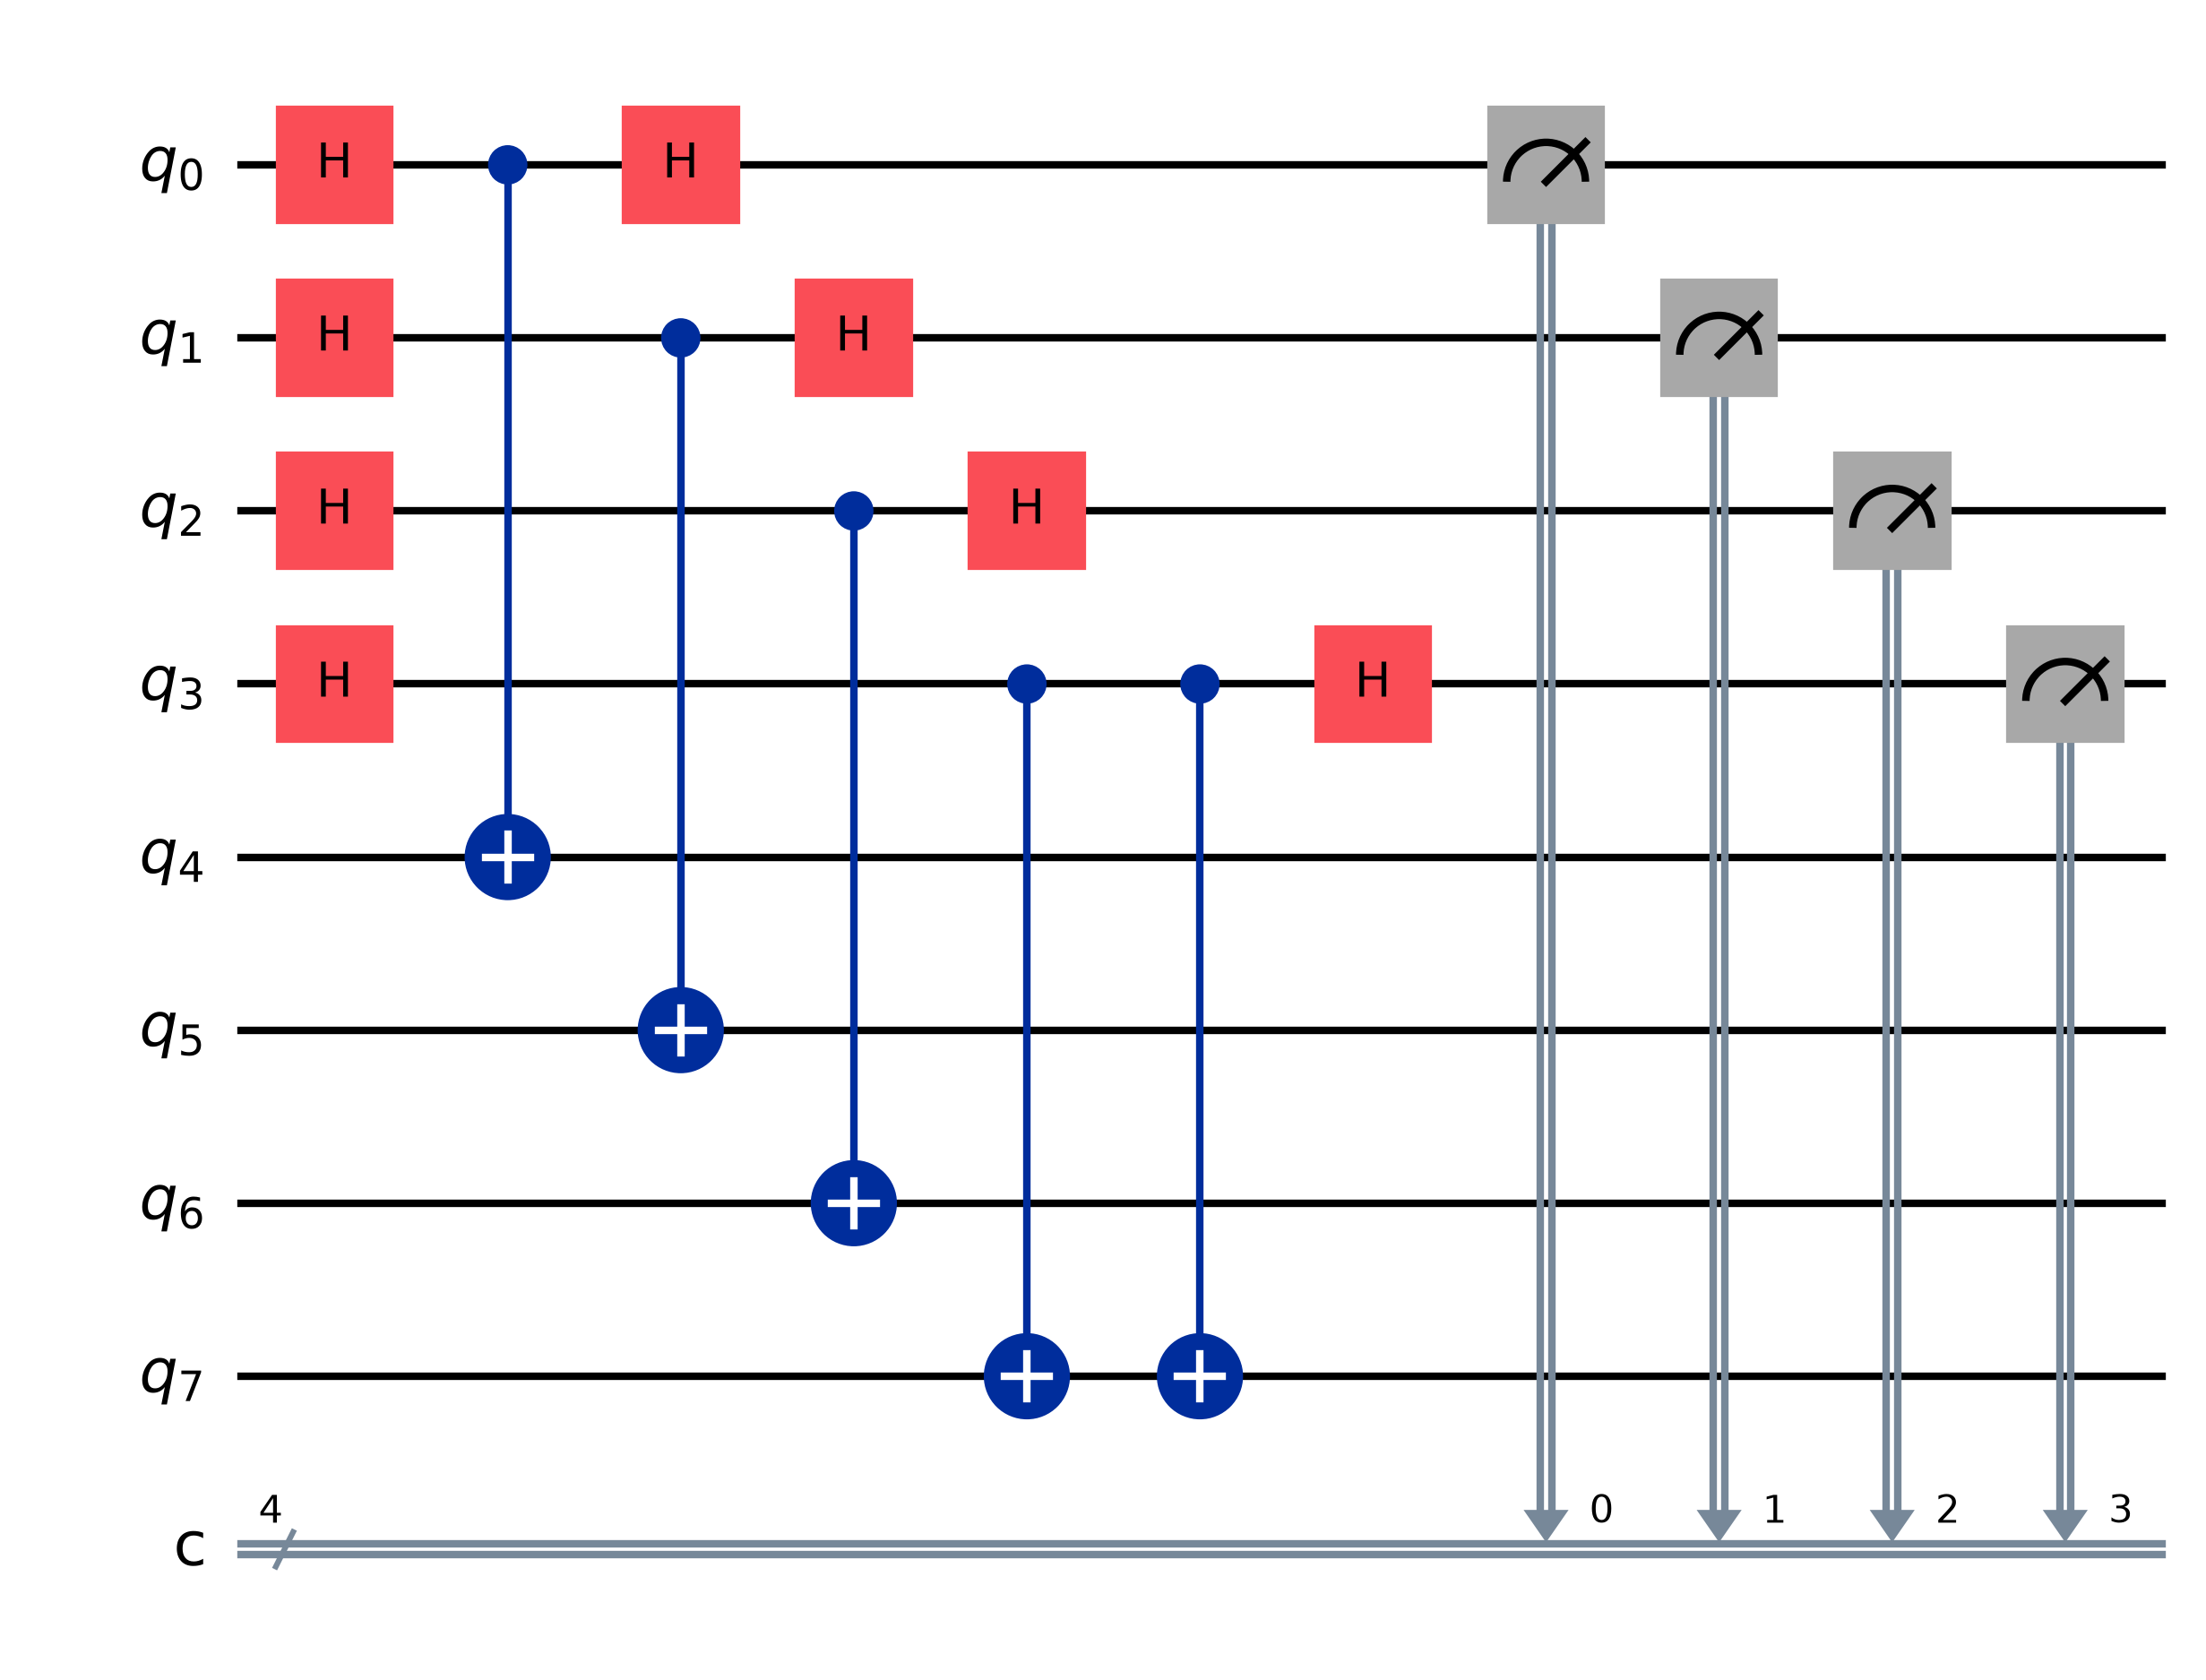

Measured equations:
  0001 . s = 0   (127 shots)
  0010 . s = 0   (118 shots)
  0011 . s = 0   (134 shots)
  0100 . s = 0   (137 shots)
  0101 . s = 0   (137 shots)
  0110 . s = 0   (113 shots)
  0111 . s = 0   (124 shots)
Independent equations: 3
Recovered s: ['1000']
Oracle queries (shots): 1024
Unique solution: True


In [7]:
# Black box: the hidden string is chosen at random and not printed
random.seed(2024)
n = 4
_secret = format(random.randrange(1, 2**n), f"0{n}b")

black_box = QuantumCircuit(2 * n)
simon_oracle(black_box, _secret)

def simon_circuit(n, oracle):
    qc = QuantumCircuit(2 * n, n)
    # Input superposition
    qc.h(range(n))
    # Black-box oracle
    qc.compose(oracle, inplace=True)
    # Interference
    qc.h(range(n))
    # Measurement
    qc.measure(range(n), range(n))
    return qc

qc = simon_circuit(n, black_box)
display(qc.draw("mpl"))

shots = 1024
counts = backend.run(transpile(qc, backend), shots=shots).result().get_counts()
print("Measured equations:")
ys = []
for y in sorted(counts):
    if y != "0" * n:
        ys.append(y)
        print(f"  {y} . s = 0   ({counts[y]} shots)")

candidates = recover_s(ys, n)
print("Independent equations:", gf2_rank(ys))
print("Recovered s:", candidates)
print("Oracle queries (shots):", shots)
print("Unique solution:", len(candidates) == 1)

In [8]:
# Verification: f(x) = f(x XOR s) for random inputs
s_found = candidates[0]

def query_black_box(x):
    qc = QuantumCircuit(2 * n, n)
    for i, bit in enumerate(reversed(x)):
        if bit == "1":
            qc.x(i)
    qc.compose(black_box, inplace=True)
    qc.measure(range(n, 2 * n), range(n))
    counts = backend.run(transpile(qc, backend), shots=1).result()
    return list(counts.get_counts())[0]

for _ in range(4):
    x = format(random.randrange(2**n), f"0{n}b")
    fx, fxs = query_black_box(x), query_black_box(xor(x, s_found))
    print(f"x = {x}: f(x) = {fx}, f(x XOR s) = {fxs}, equal = {fx == fxs}")

print("Hidden string matches:", s_found == _secret)

x = 0101: f(x) = 0101, f(x XOR s) = 0101, equal = True


x = 1001: f(x) = 0001, f(x XOR s) = 0001, equal = True


x = 0110: f(x) = 0110, f(x XOR s) = 0110, equal = True


x = 1101: f(x) = 0101, f(x XOR s) = 0101, equal = True
Hidden string matches: True


### Observation

The measured strings give **3 independent equations**, which is $n - 1$ for $n = 4$, and exhaustive GF(2) search leaves **exactly one non-zero solution**, so the recovered string is unique. Testing the black box on random inputs confirmed $f(x) = f(x \oplus s)$ in every case, and the recovered value matched the secret used to build the oracle. Technically the circuit was executed 1024 times, but a handful of shots already supplied the three independent equations.

## Task 4: Cryptographic Security Investigation

### Problem Statement

A simplified cryptographic oracle unintentionally satisfies $f(x) = f(x \oplus s)$. Compare a classical black-box attack, which queries until a collision $f(x_1) = f(x_2)$ is found and sets $s = x_1 \oplus x_2$, with Simon's algorithm, which collects equations $y_i \cdot s = 0$ and solves them. Explain why such a hidden XOR periodicity is a vulnerability.

### Program

In [9]:
# Classical collision search against a Simon oracle
def classical_attack(s):
    n = len(s)
    seen = {}
    order = random.sample(range(2**n), 2**n)
    for queries, value in enumerate(order, 1):
        x = format(value, f"0{n}b")
        fx = query_oracle_for(s, x)
        if fx in seen:
            return xor(seen[fx], x), queries
        seen[fx] = x

def query_oracle_for(s, x):
    n = len(x)
    qc = QuantumCircuit(2 * n, n)
    for i, bit in enumerate(reversed(x)):
        if bit == "1":
            qc.x(i)
    simon_oracle(qc, s)
    qc.measure(range(n, 2 * n), range(n))
    counts = backend.run(transpile(qc, backend), shots=1).result()
    return list(counts.get_counts())[0]

# Quantum: count circuit runs until n-1 independent equations exist
def quantum_attack(s):
    n = len(s)
    qc = QuantumCircuit(2 * n, n)
    qc.h(range(n))
    simon_oracle(qc, s)
    qc.h(range(n))
    qc.measure(range(n), range(n))
    memory = backend.run(transpile(qc, backend), shots=64,
                         memory=True).result().get_memory()
    ys = []
    for queries, y in enumerate(memory, 1):
        if y != "0" * n:
            ys.append(y)
        if ys and gf2_rank(ys) == n - 1:
            return recover_s(ys, n)[0], queries

random.seed(7)
print("n  classical queries  quantum queries  recovered")
for s in ["110", "1011", "10110", "110101"]:
    s_c, q_c = classical_attack(s)
    s_q, q_q = quantum_attack(s)
    print(f"{len(s)}  {q_c:>17}  {q_q:>15}  {s_c} / {s_q}")

n  classical queries  quantum queries  recovered


3                  3                6  110 / 110


4                  4                4  1011 / 1011


5                  8                6  10110 / 10110


6                 15                5  110101 / 110101


### Observation

| Parameter | Classical approach | Simon's algorithm |
| --- | --- | --- |
| Oracle queries | grows with $2^{n/2}$ (birthday bound) | about $n$ runs of the circuit |
| Hidden-string recovery | from one collision $x_1 \oplus x_2$ | from $n-1$ independent equations |
| Type of information | a full output value per query | one linear constraint per run |
| Scaling with $n$ | exponential | polynomial |
| Computational requirements | memory for all outputs seen | small GF(2) linear solve |
*Classical versus quantum attack on a hidden XOR period*

Both attacks recovered every hidden string. At these tiny sizes the two query counts are comparable and chance matters (for $n = 3$ the quantum run drew the zero string and repeated strings, so it needed 6 runs against 3 classical queries), but from $n = 5$ the classical search needs more queries, and at $n = 6$ it needed 15 against 5: **the classical count grows like $2^{n/2}$ while the quantum count grows linearly in $n$**. **A hidden XOR periodicity is a vulnerability** because it means the function is two-to-one in a structured way: an attacker who learns $s$ can produce collisions at will and learns structural information about the internal function, which a secure primitive must not leak. The model here is simplified and is not an attack on any real cipher.

## Task 5: Noise and Scalability

### Problem Statement

Implement Simon's algorithm for $n = 2, 3, 4, 5, 6$ and run it under ideal and noisy simulation (depolarizing error of 1 percent on H and 3 percent on CX). Record qubits, depth, gate count and whether the hidden string is recovered in each case, and investigate how noise affects the valid outcomes and the recovery.

### Program

In [10]:
def simon_circuit_for(s):
    n = len(s)
    qc = QuantumCircuit(2 * n, n)
    qc.h(range(n))
    simon_oracle(qc, s)
    qc.h(range(n))
    qc.measure(range(n), range(n))
    return qc

# Noise model
noise_model = NoiseModel()
error_1q = depolarizing_error(0.01, 1)
error_2q = depolarizing_error(0.03, 2)
noise_model.add_all_qubit_quantum_error(error_1q, ["h"])
noise_model.add_all_qubit_quantum_error(error_2q, ["cx"])

ideal_backend = AerSimulator()
noisy_backend = AerSimulator(noise_model=noise_model)

# Example hidden string from the manual
s = "10101"
qc = simon_circuit_for(s)
ideal_counts = ideal_backend.run(
    transpile(qc, ideal_backend), shots=1024
).result().get_counts()
noisy_counts = noisy_backend.run(
    transpile(qc, noisy_backend), shots=1024
).result().get_counts()
print("Ideal Results:", ideal_counts)
print("Noisy Results:", noisy_counts)
valid = sum(c for y, c in noisy_counts.items() if dot(y, s) == 0)
print("Noisy shots satisfying y . s = 0:", valid, "of 1024")

Ideal Results: {'00111': 59, '00010': 60, '10011': 74, '11100': 68, '10001': 59, '01000': 73, '00000': 74, '01101': 75, '11011': 62, '10110': 63, '11110': 62, '11001': 62, '01010': 53, '01111': 71, '10100': 50, '00101': 59}
Noisy Results: {'10011': 66, '11100': 62, '10100': 47, '00101': 51, '00000': 64, '11001': 69, '10000': 6, '11011': 55, '11110': 66, '01111': 64, '00010': 53, '10110': 51, '10001': 53, '00111': 57, '01010': 77, '01101': 51, '01000': 51, '01100': 3, '00100': 5, '01110': 7, '10101': 9, '11111': 2, '11000': 3, '10010': 7, '01001': 5, '10111': 6, '11101': 10, '00110': 4, '00011': 2, '11010': 4, '01011': 6, '00001': 8}
Noisy shots satisfying y . s = 0: 937 of 1024


In [11]:
# Recover s from the most frequent outcomes until n-1 equations
def recover_from_counts(counts, n):
    ys = []
    for y in sorted(counts, key=counts.get, reverse=True):
        if y == "0" * n:
            continue
        ys.append(y)
        if gf2_rank(ys) == n - 1:
            break
    found = recover_s(ys, n)
    return found[0] if len(found) == 1 else None

print("n  qubits  depth  gates  ideal recovery  noisy recovery")
for n in range(2, 7):
    s = "110101"[:n]
    qc = simon_circuit_for(s)
    compiled = transpile(qc, noisy_backend)
    ideal = ideal_backend.run(
        transpile(qc, ideal_backend), shots=1024
    ).result().get_counts()
    noisy = noisy_backend.run(compiled, shots=1024).result().get_counts()
    r_ideal = recover_from_counts(ideal, n) == s
    r_noisy = recover_from_counts(noisy, n) == s
    print(f"{n}  {2 * n:>6}  {compiled.depth():>5}  {compiled.size():>5}",
          f"  {str(r_ideal):>14}  {str(r_noisy):>14}")

n  qubits  depth  gates  ideal recovery  noisy recovery


2       4      5      8             True            True


3       6      5     12             True            True


4       8      6     17             True            True


5      10      6     21             True            True


6      12      7     26             True            True


In [12]:
# Do more shots help under noise? (n = 6)
s = "110101"
qc = transpile(simon_circuit_for(s), noisy_backend)
for shots in [64, 256, 1024, 4096]:
    noisy = noisy_backend.run(qc, shots=shots).result().get_counts()
    valid = sum(c for y, c in noisy.items() if dot(y, s) == 0)
    print(f"shots = {shots:>4}: valid fraction {valid / shots:.3f},",
          "recovered:", recover_from_counts(noisy, 6) == s)

shots =   64: valid fraction 0.844, recovered: True
shots =  256: valid fraction 0.887, recovered: True


shots = 1024: valid fraction 0.901, recovered: True
shots = 4096: valid fraction 0.884, recovered: True


### Observation

Every ideal run returns only strings with $y \cdot s = 0$ and the hidden string is recovered for all $n$. Under noise, a growing fraction of shots lands on strings that violate the condition, because the depth and the number of noisy CX gates increase with $n$. Ranking the outcomes by frequency and taking equations from the top still recovered the string in the sizes tested, since the valid strings remain the most frequent ones. **More shots sharpen the frequency ranking but do not change the fraction of valid outcomes**, so they help recovery only up to the point where noise makes an invalid string as frequent as a valid one.

## Conclusion

Simon's algorithm turned a hidden XOR symmetry into a set of linear equations over GF(2): every measured string was orthogonal to the hidden string, n-1 independent strings fixed it uniquely, and direct oracle queries confirmed the collision structure f(x) = f(x XOR s). Against a classical collision search the number of oracle calls grew only linearly with n instead of exponentially, which is why such periodicities matter for cryptographic design. Noise introduced invalid outcomes that increased with circuit depth, but frequency ranking still recovered the string for up to six input bits.